# 02 · Arms: softmax vs sigmoid, matched (Track B training)

Trains, in one core and with one recipe (v3's winning hyperparameters):

| Stage | Models | Purpose |
|---|---|---|
| `gbdt` | LightGBM + explicit ICULOS | Reference for the gate |
| `arms` | softmax × 5 seeds, sigmoid × 5 seeds (paired) | **The pre-registered primary contrast** |
| `sigmoid_fallback` | sigmoid at 3 learning rates; softmax + sigmoid with LayerScale | Only if sigmoid fails the gate (`"auto"`) |
| `warmup_control` | softmax with 2× warmup × 3 seeds | Shows the sigmoid arm's longer warmup cannot explain an arm difference |
| `kernel` | kernel × 3 seeds, kernel_raw × 1 | **Exploratory** third attention function (distance instead of dot product) |
| `controls` | shuffled-label: v3 protocol, budget-matched, budget-matched without the aux head | Control band members and the two readings agreed in `DECISIONS.md` A2 |
| `balanced` | softmax + sigmoid with FIT-only oversampling, 1 seed | Appendix only |

Matching: for a given seed both arms start from identical weights and see identical batches; only the normaliser and the warmup length (sigmoid 2×) differ. The untrained control is each run's own `init.pt`.

Everything is resumable: a finished model is skipped, an interrupted one continues from its last epoch. Expect roughly 10–12 GPU-hours on a T4 in total, so run it in several sessions and switch stages on and off in Cell 2.

Training and evaluation use v3's view: each stay's most recent 168 hours (`CFG.COVERAGE = "last"`), so `softmax_s42` here is directly comparable with v3's 0.8073.

Only FIT and VAL are loaded. Outputs are aggregates.

In [1]:
# ============================ CELL 1 · BOOTSTRAP: clone the repo, import sepsis_core from it ============================
REPO_URL = "https://github.com/Myakey/sepsis-transformer-analysis.git"
REPO_REF = "main"                                  # branch, tag or commit hash. PIN A COMMIT HASH for any run you will report.
REPO_DIR = "/content/sepsis-transformer-analysis"

import os, sys, subprocess
sys.dont_write_bytecode = True
if "google.colab" in sys.modules and not os.path.exists("/content/drive/MyDrive"):      # Drive holds the data and the checkpoints
    from google.colab import drive
    drive.mount("/content/drive")

def _git(*args, cwd=None):
    r = subprocess.run(["git", *args], cwd=cwd, capture_output=True, text=True)
    if r.returncode != 0: raise RuntimeError(f"git {' '.join(args[:2])} failed: {r.stderr.strip()[-300:]}")
    return r.stdout.strip()

def _auth_url(url):
    tok = None                                     # private repo: Colab secret GITHUB_TOKEN (Notebook access on)
    try:
        from google.colab import userdata
        tok = userdata.get("GITHUB_TOKEN")
    except Exception:
        tok = os.environ.get("GITHUB_TOKEN")
    return url.replace("https://", f"https://{tok}@") if tok else url

if not os.path.isdir(os.path.join(REPO_DIR, ".git")): _git("clone", "--quiet", _auth_url(REPO_URL), REPO_DIR)
else: _git("fetch", "--quiet", "--all", cwd=REPO_DIR)
_git("checkout", "--quiet", REPO_REF, cwd=REPO_DIR)
if REPO_REF in _git("branch", "--format=%(refname:short)", cwd=REPO_DIR).split(): _git("pull", "--quiet", "--ff-only", cwd=REPO_DIR)
_git("remote", "set-url", "origin", REPO_URL, cwd=REPO_DIR)        # never leave a token in the clone's config
CORE_COMMIT = _git("rev-parse", "HEAD", cwd=REPO_DIR)
os.environ["SEPSIS_PROJECT_ROOT"] = REPO_DIR
os.environ["SEPSIS_CORE_COMMIT"] = CORE_COMMIT
for m in [k for k in sys.modules if k == "sepsis_core" or k.startswith("sepsis_core.")]: del sys.modules[m]
if os.path.join(REPO_DIR, "Notebooks", "v4") not in sys.path: sys.path.insert(0, os.path.join(REPO_DIR, "Notebooks", "v4"))

import importlib.util
_need = [p for p in ("mlflow", "lightgbm") if importlib.util.find_spec(p) is None]
if _need: subprocess.call([sys.executable, "-m", "pip", "install", "-q", *_need])

import json, time, gc
import numpy as np, pandas as pd, torch
import sepsis_core
from sepsis_core import config as C, data, dataset, models, engine, metrics, calibration, balancing, controls, gbdt, runs, plots, tracking
print("sepsis_core", sepsis_core.__version__, "@ commit", CORE_COMMIT[:12], f"({REPO_REF})", "| torch", torch.__version__)

Mounted at /content/drive
sepsis_core 4.1.0-phase2 @ commit 0ee18eaa2e56 (main) | torch 2.14.1+cu130


In [2]:
# ============================ CELL 2 · SWITCHES ============================
SMOKE_TEST = False       # True = tiny end-to-end dry run in a separate folder (v4_smoke). Run it once before the real thing.
STAGES = dict(gbdt=True, arms=True, sigmoid_fallback="auto", warmup_control=True, kernel=True, controls=True, balanced=True)

runs.setup(smoke=SMOKE_TEST)
SEEDS        = list(C.CFG.SEEDS)[: (2 if SMOKE_TEST else 5)]
PRIMARY      = SEEDS[0]
KERNEL_SEEDS = SEEDS[: (1 if SMOKE_TEST else 3)]
WARMUP_SEEDS = SEEDS[: (1 if SMOKE_TEST else 3)]
HP = dict(C.V3_BEST_HP)                              # v3's winner, read from the file extracted from the v3 notebook
def hp_for(arm, **over): return {**HP, "arm": arm, **over}
REC = {}
print("seeds:", SEEDS, "| primary:", PRIMARY)
print("hyperparameters:", json.dumps({k: HP[k] for k in ("d_model", "num_heads", "num_layers", "ffn_mult", "dropout", "lr", "weight_decay", "batch_size", "focal_gamma", "focal_alpha", "aux_w")}))

[mlflow] connected to DagsHub: https://dagshub.com/Myakey/sepsis-attention-analysis.mlflow | experiment: sepsis-attention-v4
run=v4_last168 | smoke=False | device=cuda amp=torch.float16 | core commit=0ee18eaa2e56 | view=v3: most recent 168 h per stay | artifacts=/content/drive/MyDrive/sepsis_v4/v4_last168 | mlflow=ON https://dagshub.com/Myakey/sepsis-attention-analysis.mlflow
seeds: [42, 1042, 2042, 3042, 4042] | primary: 42
hyperparameters: {"d_model": 768, "num_heads": 8, "num_layers": 4, "ffn_mult": 3, "dropout": 0.14795346171929938, "lr": 2.5256996217084768e-05, "weight_decay": 4.989327324346609e-05, "batch_size": 32, "focal_gamma": 1.0, "focal_alpha": 0.8778585109647381, "aux_w": 0.05}


In [3]:
# ============================ CELL 3 · DATA (FIT/VAL, frozen split, FIT-only preprocessing) ============================
B = runs.prepare_mimic()

[full36] cohort: rows=3,966,669 stays=74,704 patients=56,075 pos_rate=1.1461% | split sha1=65441cff1a47 | septic stays=11,731 early-onset=65.3%
[full36] stays FIT=45,685 VAL=8,174 | rows=2,719,017 | features=36 | hour-gap violations=0 | FIT prevalence/horizon=[0.0102, 0.0091, 0.0086] | focal alpha(prevalence)=0.9907 | data hash=5fba01503a363ab7 | store loaded from cache


In [4]:
# ============================ CELL 4 · LightGBM reference (for the gate) ============================
G = None
if STAGES["gbdt"]:
    G = gbdt.fit_or_load(runs.model_dir("gbdt_iculos"), B["store"], B["pre"], B["fit_idx"], B["val_idx"], with_iculos=True)
    G_ROWS, G_LOGIT = G["rows"], gbdt.to_logit(G["scores"])
    gm = metrics.compute_metrics(B["store"], G_ROWS, G_LOGIT)
    print(f"LightGBM (+ICULOS) VAL AUROC t1/t3/t6 {gm['auroc_t1']:.4f}/{gm['auroc_t3']:.4f}/{gm['auroc_t6']:.4f} | mean {gm['auroc_mean']:.4f} | "
          f"AUPRC {gm['auprc_mean']:.4f} | trees {G['best_iter']} | top features t+1: {G['top_features'][:6]}")

[gbdt] loaded /content/drive/MyDrive/sepsis_v4/v4_last168/models/gbdt_iculos
LightGBM (+ICULOS) VAL AUROC t1/t3/t6 0.7863/0.7632/0.7498 | mean 0.7664 | AUPRC 0.0345 | trees [412, 264, 287] | top features t+1: ['FiO2_hrs_since', 'hospadm', 'WBC_ffill', 'PTT_ffill', 'age', 'Resp_mean6h']


## Primary contrast: softmax vs sigmoid, 5 paired seeds

In [5]:
# ============================ CELL 5 · THE ARMS ============================
if STAGES["arms"]:
    for seed in SEEDS:                                   # seed-major order: each pair finishes together
        for arm in ("softmax", "sigmoid"):
            nm = f"{arm}_s{seed}"; REC[nm] = runs.train_model(B, nm, hp_for(arm), seed=seed, role="primary_arm")

[softmax_s42] finished earlier -> VAL AUROC 0.8062 (soup), 0.7957 (single epoch)
[sigmoid_s42] finished earlier -> VAL AUROC 0.7992 (soup), 0.7905 (single epoch)
[softmax_s1042] finished earlier -> VAL AUROC 0.8098 (soup), 0.8040 (single epoch)
[sigmoid_s1042] finished earlier -> VAL AUROC 0.7997 (soup), 0.7989 (single epoch)
[softmax_s2042] finished earlier -> VAL AUROC 0.8050 (soup), 0.8026 (single epoch)
[sigmoid_s2042] finished earlier -> VAL AUROC 0.7955 (soup), 0.7843 (single epoch)
[softmax_s3042] finished earlier -> VAL AUROC 0.8010 (soup), 0.7949 (single epoch)
[sigmoid_s3042] finished earlier -> VAL AUROC 0.7930 (soup), 0.7856 (single epoch)
[softmax_s4042] finished earlier -> VAL AUROC 0.8058 (soup), 0.8016 (single epoch)
[sigmoid_s4042] finished earlier -> VAL AUROC 0.8052 (soup), 0.7982 (single epoch)


In [6]:
# ============================ CELL 6 · GATE, SEED SPREAD, ARM DIFFERENCE ============================
def recs_of(prefix, seeds): return [REC[f"{prefix}_s{s}"] for s in seeds if f"{prefix}_s{s}" in REC]

GATE, SEED_SUMMARY, ARM_DIFF = {}, {}, {}
for arm in ("softmax", "sigmoid"):
    rs = recs_of(arm, SEEDS)
    if not rs: continue
    SEED_SUMMARY[arm] = dict(soup=runs.seed_summary(rs), single_epoch=runs.seed_summary(rs, "metrics_single"))
    s_ = SEED_SUMMARY[arm]
    print(f"{arm:<8s} VAL AUROC over {s_['soup']['n']} seeds: soup {s_['soup']['mean']:.4f} +/- {s_['soup']['sd']:.4f} [{s_['soup']['min']:.4f}, {s_['soup']['max']:.4f}] | "
          f"best single epoch {s_['single_epoch']['mean']:.4f} +/- {s_['single_epoch']['sd']:.4f} | final total mass {[round(r['mass_per_epoch'][-1], 3) for r in rs if r['mass_per_epoch']]}")
    nm = f"{arm}_s{PRIMARY}"
    if G is not None and nm in REC:
        rows, lg = runs.val_scores(nm); assert np.array_equal(rows, G_ROWS), "row order differs between the model and LightGBM"
        GATE[arm] = metrics.gate(B["store"], rows, lg, G_LOGIT, n_boot=runs.STATE["n_boot"])
        print(f"  GATE ({nm}): {'PASS' if GATE[arm]['passed'] else 'FAIL'}")
        for p in GATE[arm]["per_horizon"]:
            print(f"    t+{p['horizon']}: AUROC - LightGBM = {p['d_auroc']:+.4f} [{p['d_lo']:+.4f}, {p['d_hi']:+.4f}] {'ok' if p['ok_auroc'] else 'FAIL'} | AUPRC lift x{p['auprc_lift']:.1f} {'ok' if p['ok_lift'] else 'FAIL'}")

print("\nsigmoid - softmax, same seed (stay-level paired bootstrap on VAL):")
for s in SEEDS:
    if f"softmax_s{s}" in REC and f"sigmoid_s{s}" in REC:
        rows, a = runs.val_scores(f"softmax_s{s}"); _, b = runs.val_scores(f"sigmoid_s{s}")
        ARM_DIFF[s] = runs.paired(B["store"], rows, a, b)
        print(f"  seed {s}: dAUROC {ARM_DIFF[s]['d']:+.4f} [{ARM_DIFF[s]['lo']:+.4f}, {ARM_DIFF[s]['hi']:+.4f}]")
if ARM_DIFF:
    d = np.array([v["d"] for v in ARM_DIFF.values()])
    ARM_DIFF_SEEDS = dict(mean=float(d.mean()), sd=float(d.std(ddof=1)) if len(d) > 1 else float("nan"), n_positive=int((d > 0).sum()), n=int(len(d)))
    print(f"  across seeds: mean {ARM_DIFF_SEEDS['mean']:+.4f}, SD {ARM_DIFF_SEEDS['sd']:.4f}, sigmoid ahead in {ARM_DIFF_SEEDS['n_positive']}/{ARM_DIFF_SEEDS['n']} seeds "
          "(a difference smaller than the seed SD is 'not resolved')")

softmax  VAL AUROC over 5 seeds: soup 0.8056 +/- 0.0032 [0.8010, 0.8098] | best single epoch 0.7998 +/- 0.0042 | final total mass [1.0, 1.0, 1.0, 1.0, 1.0]
  GATE (softmax_s42): PASS
    t+1: AUROC - LightGBM = +0.0295 [+0.0171, +0.0418] ok | AUPRC lift x5.7 ok
    t+3: AUROC - LightGBM = +0.0417 [+0.0281, +0.0536] ok | AUPRC lift x5.9 ok
    t+6: AUROC - LightGBM = +0.0481 [+0.0352, +0.0620] ok | AUPRC lift x5.7 ok
sigmoid  VAL AUROC over 5 seeds: soup 0.7985 +/- 0.0047 [0.7930, 0.8052] | best single epoch 0.7915 +/- 0.0068 | final total mass [0.251, 0.26, 0.239, 0.254, 0.264]
  GATE (sigmoid_s42): PASS
    t+1: AUROC - LightGBM = +0.0219 [+0.0096, +0.0350] ok | AUPRC lift x5.2 ok
    t+3: AUROC - LightGBM = +0.0326 [+0.0167, +0.0470] ok | AUPRC lift x5.1 ok
    t+6: AUROC - LightGBM = +0.0437 [+0.0303, +0.0581] ok | AUPRC lift x5.2 ok

sigmoid - softmax, same seed (stay-level paired bootstrap on VAL):
  seed 42: dAUROC -0.0071 [-0.0131, -0.0009]
  seed 1042: dAUROC -0.0101 [-0.0166, 

## Sigmoid fallback (pre-registered, `DECISIONS.md` A9)

Runs only if the sigmoid arm fails the gate (or if you set `sigmoid_fallback=True`). Learning-rate-only tuning at the primary seed, plus a secondary matched pair with LayerScale in **both** arms. The unmodified pair above stays the primary result; anything here is reported as a limitation.

In [7]:
# ============================ CELL 7 · SIGMOID FALLBACK ============================
FALLBACK = {}
_need = STAGES["sigmoid_fallback"] is True or (STAGES["sigmoid_fallback"] == "auto" and "sigmoid" in GATE and not GATE["sigmoid"]["passed"])
if _need:
    for mult in (0.5, 2.0, 4.0):
        nm = f"sigmoid_lr{mult:g}x_s{PRIMARY}"; REC[nm] = runs.train_model(B, nm, hp_for("sigmoid", lr=HP["lr"] * mult), seed=PRIMARY, role="sigmoid_lr_tuning")
    for arm in ("softmax", "sigmoid"):
        nm = f"{arm}_layerscale_s{PRIMARY}"; REC[nm] = runs.train_model(B, nm, hp_for(arm, layerscale=1e-4), seed=PRIMARY, role="layerscale_secondary_pair")
    for nm in [n for n in REC if "_lr" in n or "_layerscale" in n]:
        rows, lg = runs.val_scores(nm); g = metrics.gate(B["store"], rows, lg, G_LOGIT, n_boot=runs.STATE["n_boot"]) if G is not None else None
        FALLBACK[nm] = dict(auroc=REC[nm]["metrics"]["auroc_mean"], gate=(g["passed"] if g else None), gate_detail=(g["per_horizon"] if g else None))
        print(f"  {nm:<28s} VAL AUROC {FALLBACK[nm]['auroc']:.4f} | gate {'PASS' if FALLBACK[nm]['gate'] else 'FAIL'}")
    print("NOTE: the learning rate is chosen on VAL, so these numbers are optimistic; report the untuned sigmoid run next to them.")
else:
    print("fallback not needed" if "sigmoid" in GATE else "fallback not evaluated (no gate result yet)")

fallback not needed


In [8]:
# ============================ CELL 8 · WARMUP CONTROL: softmax with the sigmoid arm's 2x warmup ============================
WARMUP = {}
if STAGES["warmup_control"]:
    for seed in WARMUP_SEEDS:
        nm = f"softmax_warmup2x_s{seed}"; REC[nm] = runs.train_model(B, nm, hp_for("softmax", warmup_mult=2.0), seed=seed, role="warmup_control")
        if f"softmax_s{seed}" in REC:
            rows, a = runs.val_scores(f"softmax_s{seed}"); _, b = runs.val_scores(nm); WARMUP[seed] = runs.paired(B["store"], rows, a, b)
            print(f"  seed {seed}: softmax(2x warmup) - softmax = {WARMUP[seed]['d']:+.4f} [{WARMUP[seed]['lo']:+.4f}, {WARMUP[seed]['hi']:+.4f}]")

[softmax_warmup2x_s42] finished earlier -> VAL AUROC 0.8072 (soup), 0.7980 (single epoch)
  seed 42: softmax(2x warmup) - softmax = +0.0010 [-0.0011, +0.0032]
[softmax_warmup2x_s1042] finished earlier -> VAL AUROC 0.8091 (soup), 0.8019 (single epoch)
  seed 1042: softmax(2x warmup) - softmax = -0.0007 [-0.0017, +0.0001]
[softmax_warmup2x_s2042] finished earlier -> VAL AUROC 0.8043 (soup), 0.8015 (single epoch)
  seed 2042: softmax(2x warmup) - softmax = -0.0007 [-0.0044, +0.0032]


## Exploratory: kernel attention inside the same trunk

`z_tj = −β_h‖q_t − k_j‖²`, learned β per head. `kernel` normalises rows (a softmax over distance); `kernel_raw` does not. Same embedding, init, hyperparameters and batches. This separates the *similarity function* from the *normaliser*. It is **outside** the pre-registered primary contrast.

In [9]:
# ============================ CELL 9 · KERNEL ARMS (exploratory) ============================
if STAGES["kernel"]:
    for seed in KERNEL_SEEDS:
        nm = f"kernel_s{seed}"; REC[nm] = runs.train_model(B, nm, hp_for("kernel"), seed=seed, role="exploratory_kernel")
    try:
        nm = f"kernel_raw_s{PRIMARY}"; REC[nm] = runs.train_model(B, nm, hp_for("kernel_raw"), seed=PRIMARY, role="exploratory_kernel_raw")
    except Exception as e:                                   # unnormalised weights can diverge; that is a result, not a crash
        print(f"[kernel_raw] did not train: {type(e).__name__}: {str(e)[:200]}"); tracking.end_active_runs()
    rs = recs_of("kernel", KERNEL_SEEDS)
    if rs: SEED_SUMMARY["kernel"] = dict(soup=runs.seed_summary(rs), single_epoch=runs.seed_summary(rs, "metrics_single")); print("kernel:", SEED_SUMMARY["kernel"]["soup"])

[kernel_s42] finished earlier -> VAL AUROC 0.8040 (soup), 0.7938 (single epoch)
[kernel_s1042] finished earlier -> VAL AUROC 0.8070 (soup), 0.8013 (single epoch)
[kernel_s2042] finished earlier -> VAL AUROC 0.8043 (soup), 0.8027 (single epoch)
[kernel_raw_s42] finished earlier -> VAL AUROC 0.7960 (soup), 0.7884 (single epoch)
kernel: {'n': 3, 'mean': 0.8051055063556047, 'sd': 0.001613991389696295, 'min': 0.8040467756005563, 'max': 0.8069631356742377, 'values': [0.8040467756005563, 0.8069631356742377, 0.8043066077920203]}


## Controls

- **Shuffled-label, v3 protocol** (4 epochs, 30 % of FIT, aux head on, best epoch by VAL): the *primary* band member. Reading: "sepsis labels add nothing detectable beyond physiology learning."
- **Budget-matched** (all of FIT, the trained model's schedule and epoch count): robustness.
- **Budget-matched, aux head off**: decides whether the broader claim (nothing beyond architecture and inputs) also holds.
- **Untrained**: each primary run's own `init.pt`, already on disk.

The extra controls are reported beside the band. They never enter or move it.

In [10]:
# ============================ CELL 10 · SHUFFLED-LABEL CONTROLS ============================
if STAGES["controls"]:
    ST_SHUF, _rng = controls.shuffled_store(B["store"], B["fit_idx"])            # same random stream as v3 (SEED + 3)
    SFIT = controls.v3_fit_subset(_rng, B["fit_idx"], 0.3)
    print(f"shuffled labels: FIT rows only, prevalence kept | v3-protocol subset: {len(SFIT):,} of {len(B['fit_idx']):,} FIT stays")
    for arm in ("softmax", "sigmoid", "kernel"):
        prim = REC.get(f"{arm}_s{PRIMARY}")
        if prim is None: print(f"[{arm}] primary model not trained yet -> controls skipped"); continue
        REC[f"{arm}_shuf_v3"] = runs.train_model(B, f"{arm}_shuf_v3", hp_for(arm), seed=C.CFG.SEED + 5, role="control_shuffled_v3protocol", store=ST_SHUF, fit_idx=SFIT,
                                                 max_epochs=(1 if SMOKE_TEST else 4), patience=5, soup_k=0)
        if arm == "kernel": continue                         # exploratory arm: the primary band member only
        ep = int(prim["epochs_run"])
        REC[f"{arm}_shuf_budget"] = runs.train_model(B, f"{arm}_shuf_budget", hp_for(arm), seed=PRIMARY, role="control_shuffled_budget_matched", store=ST_SHUF,
                                                     stop_after_epochs=ep, fixed_epochs=True, soup_k=0)
        REC[f"{arm}_shuf_budget_noaux"] = runs.train_model(B, f"{arm}_shuf_budget_noaux", hp_for(arm, aux_w=0.0), seed=PRIMARY, role="control_shuffled_budget_matched_aux_off",
                                                           store=ST_SHUF, stop_after_epochs=ep, fixed_epochs=True, soup_k=0)
    print("\nsanity: a shuffled-label model must sit near AUROC 0.5 on the real VAL labels")
    for nm in [n for n in REC if "_shuf_" in n]: print(f"  {nm:<32s} VAL AUROC {REC[nm]['metrics']['auroc_mean']:.4f} | epochs {REC[nm]['epochs_run']} | aux_w {REC[nm]['hp']['aux_w']}")
    del ST_SHUF; gc.collect()

shuffled labels: FIT rows only, prevalence kept | v3-protocol subset: 13,705 of 45,685 FIT stays
[softmax_shuf_v3] finished earlier -> VAL AUROC 0.5075 (soup), 0.5075 (single epoch)
[softmax_shuf_budget] finished earlier -> VAL AUROC 0.4736 (soup), 0.5295 (single epoch)
[softmax_shuf_budget_noaux] finished earlier -> VAL AUROC 0.4836 (soup), 0.5218 (single epoch)
[sigmoid_shuf_v3] finished earlier -> VAL AUROC 0.5159 (soup), 0.5159 (single epoch)
[sigmoid_shuf_budget] finished earlier -> VAL AUROC 0.4794 (soup), 0.5337 (single epoch)
[sigmoid_shuf_budget_noaux] finished earlier -> VAL AUROC 0.4946 (soup), 0.5248 (single epoch)
[kernel_shuf_v3] finished earlier -> VAL AUROC 0.5066 (soup), 0.5066 (single epoch)

sanity: a shuffled-label model must sit near AUROC 0.5 on the real VAL labels
  softmax_shuf_v3                  VAL AUROC 0.5075 | epochs 4 | aux_w 0.05
  softmax_shuf_budget              VAL AUROC 0.4736 | epochs 14 | aux_w 0.05
  softmax_shuf_budget_noaux        VAL AUROC 0.48

## Balanced arms (appendix)

Separate models: FIT-only oversampling of positive-containing windows, same hyperparameters, one seed, recalibrated on natural-distribution VAL. They support no interpretability claim in the main text.

In [11]:
# ============================ CELL 11 · BALANCED ARMS ============================
BALANCED = {}
if STAGES["balanced"]:
    wrap = balancing.oversample_positive_windows(B["store"])
    for arm in ("softmax", "sigmoid"):
        nm = f"{arm}_bal_s{PRIMARY}"; REC[nm] = runs.train_model(B, nm, hp_for(arm), seed=PRIMARY, role="balanced_appendix", wrapper=wrap)
        rows, lg = runs.val_scores(nm); rep = runs.evaluate(B, rows, lg)
        raw = rep["calibration_raw"]; cal = rep["calibration"]
        BALANCED[arm] = dict(auroc=rep["metrics"]["auroc_mean"], auroc_ci=rep["auroc_mean_ci"], calibrator=rep["calibrator"]["method"],
                             mean_pred_raw=float(np.mean([r["mean_pred"] for r in raw])), obs_rate=float(np.mean([r["obs_rate"] for r in raw])),
                             cal_slope_after=float(np.mean([c["cal_slope"] for c in cal])), ece_after=float(np.mean([c["ece"] for c in cal])))
        if f"{arm}_s{PRIMARY}" in REC:
            _, a = runs.val_scores(f"{arm}_s{PRIMARY}"); BALANCED[arm]["vs_unbalanced"] = runs.paired(B["store"], rows, a, lg)
        print(f"  {nm}: AUROC {BALANCED[arm]['auroc']:.4f} | raw mean prediction {BALANCED[arm]['mean_pred_raw']:.3f} vs observed {BALANCED[arm]['obs_rate']:.4f} "
              f"-> after {BALANCED[arm]['calibrator']} recalibration: slope {BALANCED[arm]['cal_slope_after']:.2f}, ECE {BALANCED[arm]['ece_after']:.4f} | "
              f"balanced - unbalanced: {BALANCED[arm].get('vs_unbalanced', {}).get('d', float('nan')):+.4f}")

[balancing] FIT only: 4,566 positive windows x9 -> 82,213 items/epoch (was 45,685)
[softmax_bal_s42] arm=softmax seed=42 params=24,271,291 items/epoch=82,213 steps/epoch=2570 bs=32 lr=2.53e-05 warmup_steps=3084 | focal(a=0.878, g=1.0) aux_w=0.05 | select=auroc_mean soup_k=5


/content/sepsis-transformer-analysis/Notebooks/v4/sepsis_core/engine.py:193: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step(); release_attn_cache(model)


[softmax_bal_s42] ep00 loss=0.2917 aux=0.336 val_loss=0.1057 | AUROC 0.7064 AUPRC 0.0245 | mass 1.000 | lr 2.11e-05 | 125s
[softmax_bal_s42] ep01 loss=0.2533 aux=0.254 val_loss=0.1068 | AUROC 0.7555 AUPRC 0.0419 | mass 1.000 | lr 2.52e-05 | 124s
[softmax_bal_s42] ep02 loss=0.2372 aux=0.243 val_loss=0.1082 | AUROC 0.7794 AUPRC 0.0370 | mass 1.000 | lr 2.49e-05 | 129s
[softmax_bal_s42] ep03 loss=0.2110 aux=0.238 val_loss=0.1036 | AUROC 0.7644 AUPRC 0.0482 | mass 1.000 | lr 2.43e-05 | 132s
[softmax_bal_s42] ep04 loss=0.1787 aux=0.236 val_loss=0.1276 | AUROC 0.7347 AUPRC 0.0349 | mass 1.000 | lr 2.36e-05 | 129s
[softmax_bal_s42] ep05 loss=0.1464 aux=0.235 val_loss=0.1459 | AUROC 0.7393 AUPRC 0.0366 | mass 1.000 | lr 2.26e-05 | 130s
[softmax_bal_s42] ep06 loss=0.1170 aux=0.233 val_loss=0.1907 | AUROC 0.7335 AUPRC 0.0490 | mass 1.000 | lr 2.15e-05 | 127s
[softmax_bal_s42] ep07 loss=0.0951 aux=0.231 val_loss=0.2021 | AUROC 0.7237 AUPRC 0.0450 | mass 1.000 | lr 2.02e-05 | 123s
[softmax_bal_s42

/content/sepsis-transformer-analysis/Notebooks/v4/sepsis_core/engine.py:193: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step(); release_attn_cache(model)


[sigmoid_bal_s42] ep00 loss=0.2920 aux=0.356 val_loss=0.1072 | AUROC 0.6981 AUPRC 0.0235 | mass 0.454 | lr 1.05e-05 | 122s
[sigmoid_bal_s42] ep01 loss=0.2604 aux=0.263 val_loss=0.1078 | AUROC 0.7403 AUPRC 0.0339 | mass 0.405 | lr 2.11e-05 | 124s
[sigmoid_bal_s42] ep02 loss=0.2406 aux=0.250 val_loss=0.1121 | AUROC 0.7625 AUPRC 0.0316 | mass 0.366 | lr 2.52e-05 | 132s
[sigmoid_bal_s42] ep03 loss=0.2016 aux=0.244 val_loss=0.1180 | AUROC 0.7409 AUPRC 0.0317 | mass 0.329 | lr 2.49e-05 | 137s
[sigmoid_bal_s42] ep04 loss=0.1567 aux=0.241 val_loss=0.1515 | AUROC 0.7349 AUPRC 0.0356 | mass 0.289 | lr 2.44e-05 | 136s
[sigmoid_bal_s42] ep05 loss=0.1172 aux=0.237 val_loss=0.1812 | AUROC 0.7148 AUPRC 0.0280 | mass 0.218 | lr 2.36e-05 | 137s
[sigmoid_bal_s42] ep06 loss=0.0839 aux=0.234 val_loss=0.2402 | AUROC 0.7155 AUPRC 0.0321 | mass 0.204 | lr 2.26e-05 | 137s
[sigmoid_bal_s42] ep07 loss=0.0620 aux=0.230 val_loss=0.2584 | AUROC 0.7024 AUPRC 0.0349 | mass 0.187 | lr 2.14e-05 | 128s
[sigmoid_bal_s42

saved: /content/drive/MyDrive/sepsis_v4/v4_last168/reports/02_summary.json

model                             role                                        soup  single epochs   mass
softmax_s42                       primary_arm                               0.8062  0.7957     14  1.000
sigmoid_s42                       primary_arm                               0.7992  0.7905     13  0.251
softmax_s1042                     primary_arm                               0.8098  0.8040     14  1.000
sigmoid_s1042                     primary_arm                               0.7997  0.7989     14  0.260
softmax_s2042                     primary_arm                               0.8050  0.8026     17  1.000
sigmoid_s2042                     primary_arm                               0.7955  0.7843     17  0.239
softmax_s3042                     primary_arm                               0.8010  0.7949     17  1.000
sigmoid_s3042                     primary_arm                               0.7930  

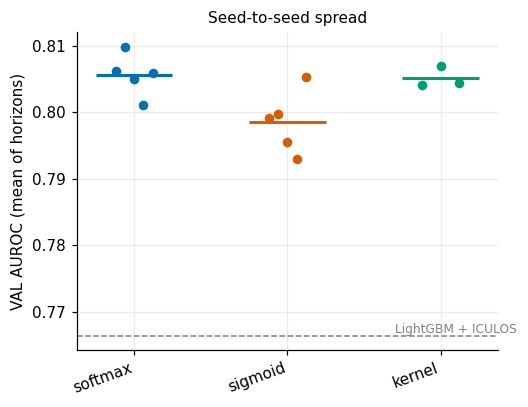

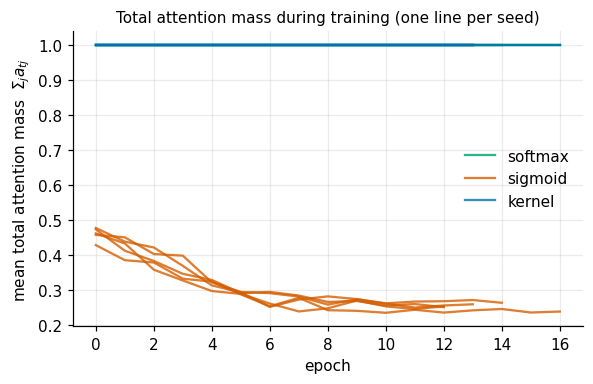

In [12]:
# ============================ CELL 12 · SUMMARY (this is what to send back) ============================
TABLE = [dict(name=n, role=r["role"], arm=r["arm"], seed=r["seed"], auroc_soup=r["metrics"]["auroc_mean"], auroc_single_epoch=r["metrics_single"]["auroc_mean"],
              auroc_t1=r["metrics"]["auroc_t1"], auroc_t3=r["metrics"]["auroc_t3"], auroc_t6=r["metrics"]["auroc_t6"], auprc_mean=r["metrics"]["auprc_mean"],
              epochs_run=r["epochs_run"], best_epoch=r["best_epoch"], soup_epochs=r["soup_epochs"], mass_last=(r["mass_per_epoch"][-1] if r["mass_per_epoch"] else None),
              epoch_sec=r["epoch_sec"]) for n, r in REC.items()]
SUMMARY = dict(time=time.strftime("%Y-%m-%dT%H:%M:%S"), core_commit=CORE_COMMIT, smoke=SMOKE_TEST, seeds=SEEDS, data_hash=B["data_hash"], cohort=B["stats"],
               gbdt=(dict(metrics=gm, best_iter=G["best_iter"]) if G is not None else None), models=TABLE, seed_summary=SEED_SUMMARY, gate=GATE,
               arm_difference_per_seed=ARM_DIFF, arm_difference_across_seeds=(ARM_DIFF_SEEDS if ARM_DIFF else None), sigmoid_fallback=FALLBACK, warmup_control=WARMUP,
               balanced=BALANCED)
runs.save_json(SUMMARY, "02_summary.json")
print(f"\n{'model':<34s}{'role':<40s}{'soup':>8s}{'single':>8s}{'epochs':>7s}{'mass':>7s}")
for t in TABLE:
    print(f"{t['name']:<34s}{t['role']:<40s}{t['auroc_soup']:>8.4f}{t['auroc_single_epoch']:>8.4f}{t['epochs_run']:>7d}{(t['mass_last'] if t['mass_last'] is not None else float('nan')):>7.3f}")
groups = {a: [r["metrics"]["auroc_mean"] for r in recs_of(a, SEEDS)] for a in ("softmax", "sigmoid", "kernel") if recs_of(a, SEEDS)}
if groups: plots.seed_strip(groups, runs.figure_path("02_seed_spread.png"), ref=({"LightGBM + ICULOS": gm["auroc_mean"]} if G is not None else None))
prim = [r for r in REC.values() if r["role"] in ("primary_arm", "exploratory_kernel")]
if prim: plots.mass_curves(prim, runs.figure_path("02_total_mass.png"))

## What to send back

The printed output of Cell 6 (gate, seed spread, arm difference), Cell 10 (shuffled-label sanity) and Cell 12 (summary table), or the file `reports/02_summary.json`. All of it is aggregate.

Not in this notebook: the optional re-run of v3 ladder rungs C1/C3/C4 with 3 seeds (low priority in the brief). Say the word and I add it.